Me he cansado de transcribir los ejercicios. Hola

$\textbf{1. Regla del Trapecio}$

a) Primero debo de leer los datos del archivo. Reciclaré por segunda vez el código del otro día.

In [2]:
archivo = open("velocidades.txt", "r")
lista = []
for i in archivo.readlines():
    lista.append(i)
lista2 = []
for i in lista:
    lista2.append(i.split())
t = []
v_x = []
for i in lista2:
    t.append(float(i[0]))
    v_x.append(float(i[1]))

No sé cómo cambia la velocidad cada segundo, pero como hay que usar la regla del trapecio, convendrá considerar que cambia linealmente.
Con la regla del trapecio, entonces, tengo que sumar dos velocidades consecutivas y dividir sobre dos. Así: $ \Delta x_i = \frac{v_i + v_{i+1}}{2} \Delta t$. En este ejercicio, convenientemente $\Delta t = 1$. Esto es lo mismo que tomar $A_k = \frac{h}{2} \left[ f(a+(k-1)h)+f(a+kh) \right]$ haciendo $h=\Delta t$ y $f = v$.

Hago la suma, entonces:

In [4]:
x = v_x[-1] #la condición inicial
for i in range(1,100):
    x = x + (v_x[i]+v_x[i+1])/2

In [37]:
x

8.521493

Para hacer la gráfica de la posición, debo de guardar cada una de las iteraciones anteriores en una lista, pues esas son las posiciones en cada momento.

In [38]:
x_t = [0,v_x[-1]] #posiciones en el tiempo
x = v_x[-1] #la condición inicial
for i in range(1,100):
    x_t.append(x) #agrego las posiciones
    x = x + (v_x[i]+v_x[i+1])/2

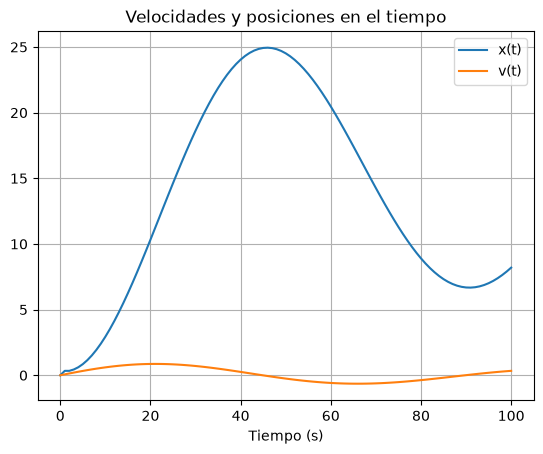

In [42]:
import matplotlib.pyplot as plt
plt.title("Velocidades y posiciones en el tiempo")
plt.plot(t,x_t, label = "x(t)")
plt.grid()
plt.plot(t,v_x, label = "v(t)")
plt.xlabel("Tiempo (s)")
plt.legend()

$\textbf{2. El límite de difracción de un telescopio}$

a) Pues formulazo, ¿no?

R: ¿Cómo defino a la f dentro de la función sin tener que escribirla explícitamente?
R2: pues teniendo fé

In [43]:
import numpy as np #para sacar las funciones

In [44]:
def simp(f,a,b,n): #esta es la función de simpson que hice en clase
    """Esta función te calcula una integral usando parábolas y el método de Simpson."""
    h = (b-a)/n
    I = (h/3)*(f(a)+f(b))
    for k in range(1,int(n/2)):
        I = I + (h/3)*(2*f(a+2*k*h)) #sumo los términos pares
    for k in range(1,int(n/2+1)):
        I = I + (h/3)*(4*f(a+(2*k-1)*h)) #sumo los términos impares
    return I

In [45]:
def J(m,x):
    def f(t):
        return np.cos(m*t-x*np.sin(t)) #defino a la función a integrar dentro de la función J

    return simp(f,0,np.pi,1000)/np.pi
        
    

In [46]:
J(0,1) #funcionó. O eso parece, al menos

np.float64(0.7651976865579673)

Para graficar simplemente uso la función. Veré si se puede hacer directo, y si no, pues usaré listas.

In [47]:
a

(array([[-1.        , -0.95918367, -0.91836735, ...,  0.91836735,
          0.95918367,  1.        ],
        [-1.        , -0.95918367, -0.91836735, ...,  0.91836735,
          0.95918367,  1.        ],
        [-1.        , -0.95918367, -0.91836735, ...,  0.91836735,
          0.95918367,  1.        ],
        ...,
        [-1.        , -0.95918367, -0.91836735, ...,  0.91836735,
          0.95918367,  1.        ],
        [-1.        , -0.95918367, -0.91836735, ...,  0.91836735,
          0.95918367,  1.        ],
        [-1.        , -0.95918367, -0.91836735, ...,  0.91836735,
          0.95918367,  1.        ]], shape=(50, 50)),
 array([[3.58853831e-09, 3.58853831e-09, 3.58853831e-09, ...,
         3.58853831e-09, 3.58853831e-09, 3.58853831e-09],
        [5.63781291e-09, 5.63781291e-09, 5.63781291e-09, ...,
         5.63781291e-09, 5.63781291e-09, 5.63781291e-09],
        [8.93832202e-10, 8.93832202e-10, 8.93832202e-10, ...,
         8.93832202e-10, 8.93832202e-10, 8.93832202e-10

b) Para eso, primero tengo que husmear en scipy

In [48]:
import scipy as sp

In [49]:
sp.integrate?

Type:        module
String form: <module 'scipy.integrate' from '/usr/lib64/python3.14/site-packages/scipy/integrate/__init__.py'>
File:        /usr/lib64/python3.14/site-packages/scipy/integrate/__init__.py
Docstring:  
Integration and ODEs (:mod:`scipy.integrate`)

.. currentmodule:: scipy.integrate

Integrating functions, given function object

.. autosummary::
   :toctree: generated/

   quad          -- General purpose integration
   quad_vec      -- General purpose integration of vector-valued functions
   cubature      -- General purpose multi-dimensional integration of array-valued functions
   dblquad       -- General purpose double integration
   tplquad       -- General purpose triple integration
   nquad         -- General purpose N-D integration
   tanhsinh      -- General purpose elementwise integration
   fixed_quad    -- Integrate func(x) using Gaussian quadrature of order n
   newton_cotes  -- Weights and error coefficient for Newton-Cotes integration
   lebedev_rule
 

Abrí eso, pero al chile no le entiendo, no dice cómo usarlas (en un lenguaje que pueda entender, al menos).

Ya investigué.

In [50]:
sp.integrate.simpson?

Signature: sp.integrate.simpson(y, x=None, *, dx=1.0, axis=-1)
Docstring:
Integrate y(x) using samples along the given axis and the composite
Simpson's rule. If x is None, spacing of dx is assumed.

Parameters
----------
y : array_like
    Array to be integrated.
x : array_like, optional
    If given, the points at which `y` is sampled.
dx : float, optional
    Spacing of integration points along axis of `x`. Only used when
    `x` is None. Default is 1.
axis : int, optional
    Axis along which to integrate. Default is the last axis.

Returns
-------
float
    The estimated integral computed with the composite Simpson's rule.

See Also
--------
quad : adaptive quadrature using QUADPACK
fixed_quad : fixed-order Gaussian quadrature
dblquad : double integrals
tplquad : triple integrals
romb : integrators for sampled data
cumulative_trapezoid : cumulative integration for sampled data
cumulative_simpson : cumulative integration using Simpson's 1/3 rule

Notes
-----
For an odd number of sam

In [51]:
def J_sp(m,x):
    t = np.linspace(0,np.pi,1000)
    y = np.cos(m*t-x*np.sin(t))
    return sp.integrate.simpson(y,x=t)/np.pi

In [52]:
#si lo hice bien, debería de salir algo parecido:
print(J(0,1))
print(J_sp(0,1))

0.7651976865579673
0.7651976865579462


In [53]:
#Bien. Ahora, solo graficaré una de ellas

Text(0.5, 1.0, 'Comparación')

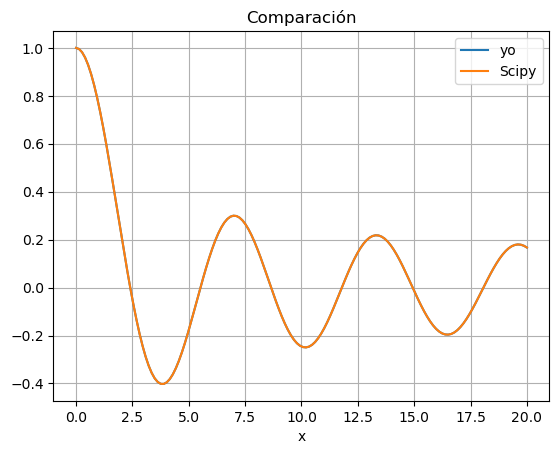

In [54]:
import matplotlib.pyplot as plt
x = np.linspace(0,20,150)
j0 = J(0,x)
j0sp = [J_sp(0,i) for i in x] #escribí esto así porque me daba un error que no entendí
plt.plot(x,j0, label = "yo")
plt.plot(x,j0sp, label = "Scipy")
plt.legend()
plt.grid()
plt.xlabel("x")
plt.title("Comparación")

In [55]:
#pues van duras

Para el density plot tendré que usar meshgrid como lo hemos estado usando en clase. Como quieren la imagen cuadrada, me veré obligado a usar las fórmulas de coordenadas polares. Además de eso, tendré que definir a mano el valor de la intensidad cuando r = 0, de la misma forma que ya quité un infinito en una tarea anterior.

Antes, me convendrá ver unidades.

$500 \ nm = 500 \times 10^{-9} m =  0.5 \times 10^{-6} m = 0.5 \mu \ m$

Con esto, me puedo tomar $r \in [0,1] \ \mu m$

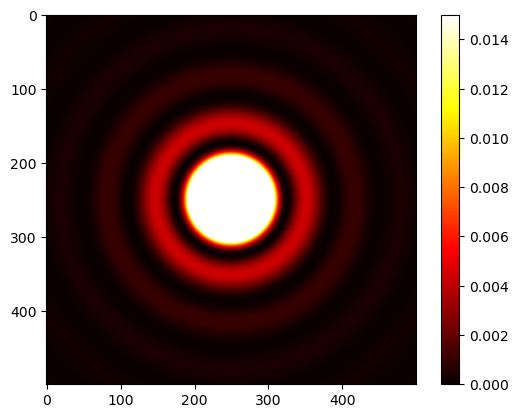

In [56]:
X=np.linspace(-1,1,500)
Y=np.linspace(-1,1,500)
x,y=np.meshgrid(X,Y) #este es el plano
k = 2*np.pi/0.5 #defino la k
r = np.sqrt(x**2 + y**2) #defino los valores de r
I = (J(1,k*r)/(k*r))**2 #saco los valores de I, lo que quiero graficar
plt.imshow(I, cmap = "hot", vmin=0, vmax=0.015) #alteré la escala de colores para que se vieran el resto de anillos
plt.colorbar()

In [57]:
#plt.imshow?

$\textbf{3. Capacidad calorífica de un sólido}$

a) Para hacer tal cosa, primero debo de programar el método de cuadratura de gauss. Debo buscar, de nuevo, en la bibliteca de SciPy. Esta vez en SciPy.Special

In [1]:
import scipy as sp

In [7]:
#sp.special? mucho texto, ya lo leí (en realidad, no)

Lo que ocupo está ahí en medio, en algún lado. Se ve así:

In [8]:
#sp.special.roots_legendre? ajá

Efectivamente, esa cosa hace todo el trabajo duro. Bastará con llamar a esa función y luego re-escalar los puntos de muestra

In [6]:
import numpy as np
from scipy.special import roots_legendre #solo quiero esa función. La bilblioteca es masiva, no ocupo toda

In [10]:
x_k, w_k = roots_legendre(2)

In [11]:
x_k

array([-0.57735027,  0.57735027])

In [13]:
w_k #funciona

array([1., 1.])

Lo que resta es nomas aplicar los formulazos para hacer la integración sobre un intervalo $[a,b]$. Los pondré aquí:

$x_k' = \frac{b-a}{2}x_k + \frac{b+a}{2}$, $\omega_k' = \frac{b-a}{2} \omega_k$

$\displaystyle\int_a^b f(x)dx \simeq \displaystyle\sum_{k=1}^N \omega_k' f(x_k')$

Notar que los pesos solo están reescalados por una constante, así que puedo ahorrarme el reescalar cada uno y simplemente puedo multiplicar la suma final por ese factor. Esto no se puede hacer con los puntos de muestra, así que esos sí los reescalaré en cada iteración. Y pues ya

In [41]:
def gauss(f,a,b,n): #ocuparé una funqueción a integrar f, el intervalo a,b y la cantidad de puntos n
    import numpy as np
    from scipy.special import roots_legendre
    x_k, w_k = roots_legendre(n) #saco las raíces y puntos
    I = 0 #parto de algún punto, 0 está bien
    for k in range(n):
        xk = ((b-a)/2)*x_k[k]+(b+a)/2 #reescalo los puntos de muestra
        I = I +w_k[k]*f(xk)
    return ((b-a)/2)*I

In [15]:
#la probaré 
def f(x):
    return np.sin(x)

In [17]:
gauss(f,-5,5,50) #parece que jala

np.float64(1.3444106938820255e-16)

In [18]:
#Ahora a hacer la función esa

In [19]:
def Cv(T): #solo pediré la temperatura
    v = 0.001 #el volumen en las unidades correctas
    rho = 6.022*(10**(28)) #la densidad
    tD = 428 #la temperatura de Debye
    kb = 1.380649*(10**(-23)) #constante de boltzmann sacada de wikipedia, la mejor fuente de todas, solo superada por tiktok y gemini
    def f(x):
        return ((x**4)*np.exp(x))/((np.exp(x)-1)**2) #defino la función a integrar, ya vi que lo puedo hacer dentro de otra definición
    I = gauss(f,0,(tD/T),50) #realizo la integral con 50 puntos de muestra
    return 9*v*rho*kb*((T/tD)**3)*I #le pongo las constantes

b) Estoy tan desensibilizado que ya ni siquiera voy a explicar qué voy a hacer

Text(0.5, 0, 'Temperatura (K)')

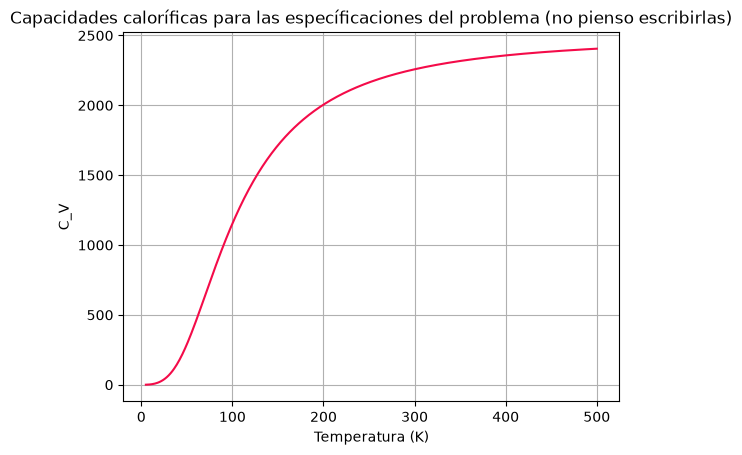

In [28]:
import matplotlib.pyplot as plt
T = range(5,501) #rango de temperaturas
cvs = [Cv(i) for i in T] #los coeficientes, escrito así porque no me deja meter arrays en la función.
plt.plot(T,cvs, color = '#F40B49')
plt.grid()
plt.title('Capacidades caloríficas para las específicaciones del problema (no pienso escribirlas)')
plt.ylabel('C_V')
plt.xlabel('Temperatura (K)')

$\textbf{4. Incertidumbre cuántica del oscilador armónico}$

Ay. Pues hay que usar esa recursividad de alguna forma, a ver qué sale

In [29]:
def H(n,x):
    if n == 0:
        return 1
    if n == 1:
        return 2*x
    return 2*x*H(n-1,x)-2*(n-1)*H(n-2,x) #utilizo la fórmula recursiva para n, en lugar de n+1

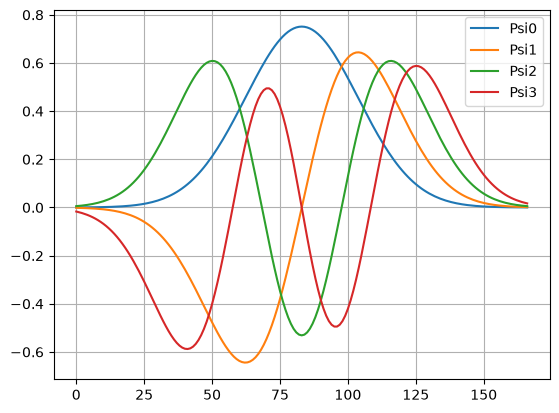

In [35]:
from math import factorial
x = np.linspace(-4,4, 167) #rango
H0 = [H(0,i) for i in x] #polinomio 0
H1 = [H(1,i) for i in x] #polinomio 1
H2 = [H(2,i) for i in x] #polinomio 2
H3 = [H(3,i) for i in x] #polinomio 3

#ahora, procederé a copiar y pegar esto 4 veces
psi0=(1/np.sqrt((2**0)*factorial(0)*np.sqrt(np.pi)))*(np.exp((-x**2)/2))*H0
plt.plot(psi0, label = 'Psi0')
#ja

#ahora, procederé a copiar y pegar esto 4 veces
psi1=(1/np.sqrt((2**1)*factorial(1)*np.sqrt(np.pi)))*(np.exp((-x**2)/2))*H1
plt.plot(psi1, label = 'Psi1')
#ja

#ahora, procederé a copiar y pegar esto 4 veces
psi2=(1/np.sqrt((2**2)*factorial(2)*np.sqrt(np.pi)))*(np.exp((-x**2)/2))*H2
plt.plot(psi2, label = 'Psi2')
#ja

#ahora, procederé a copiar y pegar esto 4 veces
psi3=(1/np.sqrt((2**3)*factorial(3)*np.sqrt(np.pi)))*(np.exp((-x**2)/2))*H3
plt.plot(psi3, label = 'Psi3')
#ja

plt.legend()
plt.grid()

c) Creo que mi función tal como está ahora se tardará bastante

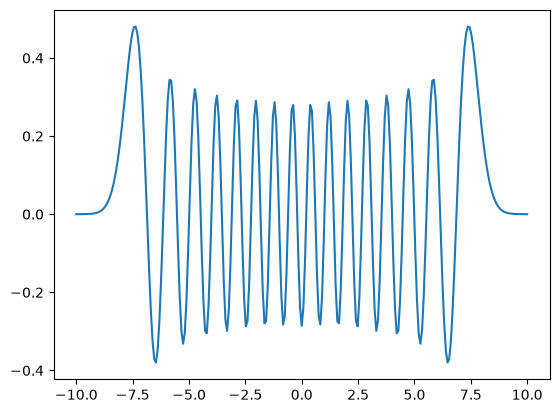

In [36]:
from math import factorial
x = np.linspace(-10,10, 267) #rango
H30 = [H(30,i) for i in x] #polinomio 0
#ahora, procederé a copiar y pegar esto 4 veces
psi30=(1/np.sqrt((2**30)*factorial(30)*np.sqrt(np.pi)))*(np.exp((-x**2)/2))*H30
plt.plot(x,psi30, label = 'Psi30')
#ja


Convendrá optimizar la función. La recursividad hace que se calculen todos los n polinomios de hermite que le pida n veces, pero solo necesito 3, el que pido y los dos anteriores, los demás los puedo desechar, es decir, los puedo redefinir

In [37]:
def H(n,x):
    if n == 0:
        return 1
    if n == 1:
        return 2*x

    H0 = 1
    H1 = 2*x #los primeros dos que se usarán para calcular todos los demás, pero luego los borraré

    for i in range(2,n+1): #ya no necesito los primeros dos, y llego hasta n
        H2 = 2*x*H1-2*(i-1)*H0 #utilizo la fórmula de recursiva
        H0 = H1 #desecho el primer polinomio
        H1 = H2 #desecho el segundo polinomio
    return  H2

Puedo regenerar la gráfica de arriba con esta nueva función. Efectivamente, ya no tarda tanto

c) son solo formulazos, salvo por la integral sobre todo R. simplemente tomaré un intervalo de integración tan ridiculamente grande como se me ocurra

In [119]:
n = 5 #el estado cuántico

def f(x):
    return (x**2)*(np.abs((1/np.sqrt((2**n)*factorial(n)*np.sqrt(np.pi)))*(np.exp((-x**2)/2))*H(n,x)))**2 #defino la función de esta forma un tanto fea, pero creo que funcionará

incert = np.sqrt(gauss(f,-10,10,100))
print(incert)

2.3452078799117166


Es curioso porque no necesité un intervalo tan grande. De hecho, uno muy grande hizo que se fuera a cero. Supongo que tiene que ver con la exponencial negativa, decae brutalmente rápido.

$\textbf{5. Atracción gravitacional de una lámina uniforme}$

a) No voy a hacer eso.

b) Pues no parece demasiado complicado, siempre y cuando adapte bien a mi función de gauss

In [2]:
def gauss2(f,a,b,n): #en principio, ocuparé las mismas entradas. El intervalo de integración lo dejo igual porque, al menos, para este ejercicio es el mismo en ambas coordenadas.
    import numpy as np
    from scipy.special import roots_legendrea
    x_i, w_i = roots_legendre(n) #saco las raíces y puntos para la primera coordenada
    y_j, w_j = roots_legendre(n) #saco las raíces y puntos para la segunda coordenada
    I = 0 #parto de algún punto, 0 está bien
    for i in range(n):a
        xi = ((b-a)/2)*x_i[i]+(b+a)/2 #reescalo los puntos de la primera coordenada
        for j in range(n):
            yj = ((b-a)/2)*y_j[j]+(b+a)/2 #reescalo los puntos de la segunda coordenada. Es importante que vayan en for diferentes para que se combinen los índices.
            I = I +w_i[i]*w_j[j]*f(xi,yj) #cambiará la definición de f.
    return (((b-a)/2)**2)*I #la constante va al cuadrado porque ahora hay dos contribuciones

In [3]:
def f(x,y):
    return 1

In [4]:
gauss2(f,-1,1,50)

np.float64(4.000000000000004)

In [5]:
z=1 #estos son experimentos

In [28]:
import numpy as np
z=np.linspace(1/2,10,1000) #defino los valores de z
G=6.674*(10**(-11))
sig = 10000/(10*10) #densidad de masa superficial
L = 10
def f(x,y):
    return (x**2+y**2+z**2)**(-3/2) 
F = G*sig*z*gauss2(f,-L/2,L/2,100)

Text(0.5, 1.0, 'Fuerza de una placa sobre una partícula')

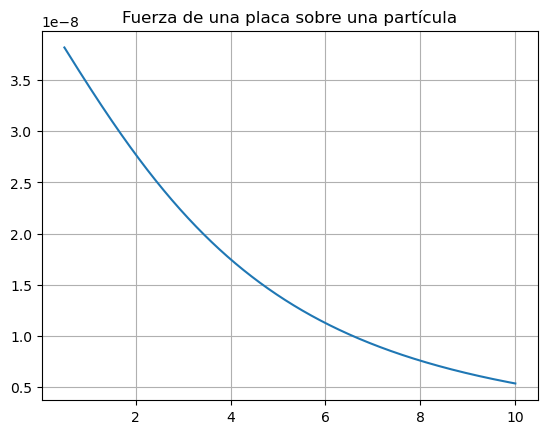

In [29]:
import matplotlib.pyplot as plt
plt.plot(z,F)
plt.grid()
plt.title('Fuerza de una placa sobre una partícula')

In [25]:
F[1]

np.float64(3.305861446792498e-11)

c) Con "la forma en la que hemos realizado el cálculo" se refiere a la definición que di sobre gauss para dos variables, ¿o sobre cómo coloqué la z dentro de la función?

In [96]:
a = np.linspace(0,1,10)

In [97]:
a

array([0.        , 0.11111111, 0.22222222, 0.33333333, 0.44444444,
       0.55555556, 0.66666667, 0.77777778, 0.88888889, 1.        ])

In [98]:
def f(x,y):
    return (x+a)**(-1)

In [99]:
gauss2(f,0,1,100)

array([10.37475504,  2.30258509,  1.70474809,  1.38629436,  1.178655  ,
        1.02961942,  0.91629073,  0.82667857,  0.7537718 ,  0.69314718])

Claro, seguramente se deba a la indefinición que hay en r = 0. En este cálculo, y creo que en el del ejercicio también, no aparece, pero ciertamente debería de estar considerado. En concreto, ocurre a su alrededor (antes de z = 1/2, por lo que veo en la gráfica).
Lo pospondré por ahora, pero quizá sirva sacar esa región del cálculo, o calcularla por aparte de otra manera (pues el resto funciona bastante bien)

In [11]:
import numpy as np
z=np.linspace(0,1/2,1000) #defino los valores de z
G=6.674*(10**(-11))
sig = 10000/(10*10) #densidad de masa superficial
L = 10
def f(x,y):
    return (x**2+y**2+z**2)**(-3/2) 
F12 = G*sig*z*gauss2(f,-L/2,L/2,20)

Text(0.5, 1.0, 'Fuerza de una placa sobre una partícula')

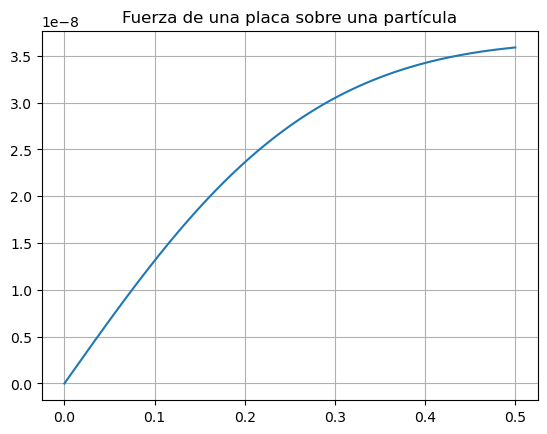

In [12]:
import matplotlib.pyplot as plt
plt.plot(z,F12)
plt.grid()
plt.title('Fuerza de una placa sobre una partícula')

Pues sigue fallando si solo calculo eso. Buscaré el cambio de variable que me sugirió Joel

El intervalo problemático es $[0,1/2]$, se me sugirió extenderlo con un cambio de variable. ¿pero de quién? ¿De z?, ¿de x?, ¿de y?

Pues de z, lo que tengo que modificar es z. El cambio de variable debe de ir sobre z. Quizá sirva: $u = 2z-1$. u va de -1 a 1 cuando z va de $0$ a $1/2$ ¿Puedo hacer la integral de 0 a 1?

Text(0.5, 1.0, 'Fuerza de una placa sobre una partícula')

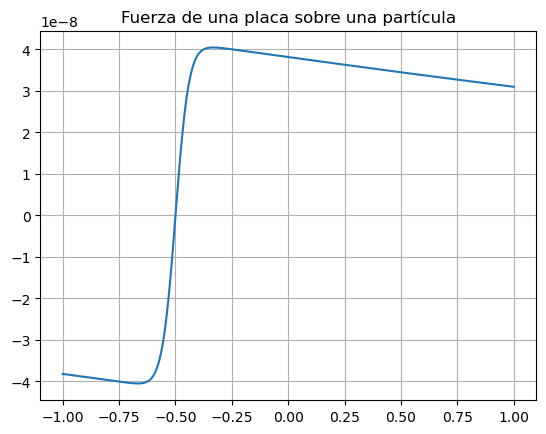

In [32]:
import numpy as np
z=np.linspace(-1,1,1000) #defino los valores de z
G=6.674*(10**(-11))
sig = 10000/(10*10) #densidad de masa superficial
L = 10
def f(x,y):
    return (x**2+y**2+(z+1/2)**2)**(-3/2) 
F12 = G*sig*(z+1/2)*gauss2(f,-L/2,L/2,100)
import matplotlib.pyplot as plt
plt.plot(z,F12)
plt.grid()
plt.title('Fuerza de una placa sobre una partícula')

Nop

$\textbf{6. Rejillas de difracción}$

a) ¿Qué les dio por preguntar estas cosas? (Es llanto)

Al menos, eso es más fácil. La distribución $q(u)=sen^2 (\alpha u)$ presenta regiones en las que se deja pasar toda la luz y regiones donde no pasa nada. No es osado pensar que la distancia entre dos consecutivas es la distancia entre las rendijas, cualquiera de ellas. Lo calcularé para las partes donde pasa toda la luz (donde deberían de estar esas aperturas) por ser más intuitivo, aunque no es la cuenta más sencilla:

$sen^2(\alpha u) = 1 \leftrightarrow \alpha u = \frac{\pi}{2} + k \pi = \pi (1/2+k) \rightarrow u = \frac{\pi}{\alpha}(1/2+k)$, para $k \in \mathbb{Z}$

Para dos de estas rendijas consecutivas, $k$ y $k+1$, la distancia entre ellas es: $d = \frac{\pi}{\alpha}(1/2+k+1)- \frac{\pi}{\alpha}(1/2+k) = \frac{\pi}{\alpha}(1/2+k+1-1/2-k)$

$\therefore d = \frac{\pi}{\alpha}$

b) otro formulazo

In [11]:
def q(u):
    d=20*(10**(-6)) #separación
    return (np.sin((np.pi/d)*u))**2 #despejé alfa en función de la distancia.

In [12]:
q(np.pi/2)

np.float64(0.29757036847630064)

c) supongo que quieren que esas 10 rendijas estén separadas todas por los 20 $\mu m$ de antes. Entonces la rejilla medirá en total $\omega = 200 \mu m = 2 \times 10^{-4} \ m$
El foco ya está en metros: $f= 1 \ m$; la longitud de onda es: $\lambda = 500 \ nm = 500 \times 10^{-9} = 5 \times 10^{-7} \ m$. $x = 10 \ cm = 10 \times 10^{-2} = 0.1 \ m$

In [13]:
#pruebas
def f(x):
    return np.exp(1j*x)

In [14]:
f(np.pi)

np.complex128(-1+1.2246467991473532e-16j)

In [15]:
gauss(f,0,1,100)

np.complex128(0.8414709848078966+0.45969769413186035j)

In [16]:
simp(f,0,1,100)

NameError: name 'simp' is not defined

Parece que cualquiera de los dos es capaz de lidiar con números complejos. Entonces eso no será un problema. Elegiré Gauss solo porque parece ser un poquito más rápido, pero los ejercicios anteriores ya probaron que es muy susceptible al intervalo de integración; pero creo que ya sé qué hacer.

In [65]:
def gauss(f,a,b,n): #ocuparé una funqueción a integrar f, el intervalo a,b y la cantidad de puntos n
    import numpy as np
    from scipy.special import roots_legendre
    x_k, w_k = roots_legendre(n) #saco las raíces y puntos
    I = 0 #parto de algún punto, 0 está bien
    for k in range(n):
        xk = ((b-a)/2)*x_k[k]+(b+a)/2 #reescalo los puntos de muestra
        I = I +w_k[k]*f(xk)
    return ((b-a)/2)*I

In [66]:
om = 2*(10**(-4)) #anchura
ff = 1 #foco
l = 5 * (10**(-7)) #longitud de onda
x = np.linspace(-0.05,0.05,50) #toda la pantalla
def f(u):
    return np.sqrt(q(u))*np.exp((1j*2*np.pi*x*u)/(l*ff)) #todo esto pura fé, verdad de Dios.
i = gauss(f,-om/2,om/2,10)
I = np.abs(i)**2

In [67]:
X=np.linspace(-1,1,50)
Y=np.linspace(-1,1,50)
x,y=np.meshgrid(X,Y) #este es el plano

No sé cómo hacerlo, pues no tengo un arreglo bidimensional como en otros casos. Quizá, bastaría con copiar y pegar los valores de I sobre toda una vertical, de tal manera que tenga una línea vertical con el mismo color, ¿cómo hago eso?

Hasta aquí llego por hoy

In [71]:
len(I)

50

In [72]:
II = np.zeros([len(I),len(I)],float)

In [77]:
II

array([[3.58853831e-09, 5.63781291e-09, 8.93832202e-10, ...,
        8.93832202e-10, 5.63781291e-09, 3.58853831e-09],
       [3.58853831e-09, 5.63781291e-09, 8.93832202e-10, ...,
        8.93832202e-10, 5.63781291e-09, 3.58853831e-09],
       [3.58853831e-09, 5.63781291e-09, 8.93832202e-10, ...,
        8.93832202e-10, 5.63781291e-09, 3.58853831e-09],
       ...,
       [3.58853831e-09, 5.63781291e-09, 8.93832202e-10, ...,
        8.93832202e-10, 5.63781291e-09, 3.58853831e-09],
       [3.58853831e-09, 5.63781291e-09, 8.93832202e-10, ...,
        8.93832202e-10, 5.63781291e-09, 3.58853831e-09],
       [3.58853831e-09, 5.63781291e-09, 8.93832202e-10, ...,
        8.93832202e-10, 5.63781291e-09, 3.58853831e-09]], shape=(50, 50))

In [76]:
for i in range(len(I)):
    II[i] = I

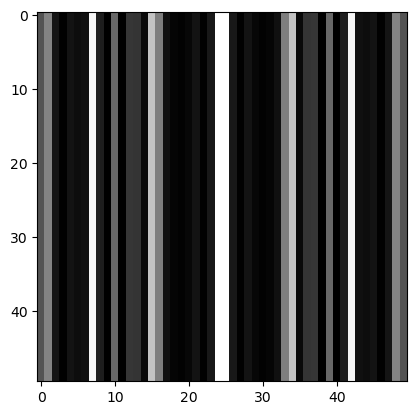

In [81]:
plt.imshow(II)
plt.gray()

?????????????????